# Basics of Beam Hardening

In [1]:
import itertools
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import profile_line
from skimage.transform import radon, iradon, rescale
from skimage.data import shepp_logan_phantom, camera, checkerboard, coins, moon, brain
from skimage import img_as_float

Finding values for and defining $\mu$ with values from the NIST XCOM database: https://physics.nist.gov/PhysRefData/Xcom/html/xcom1.html

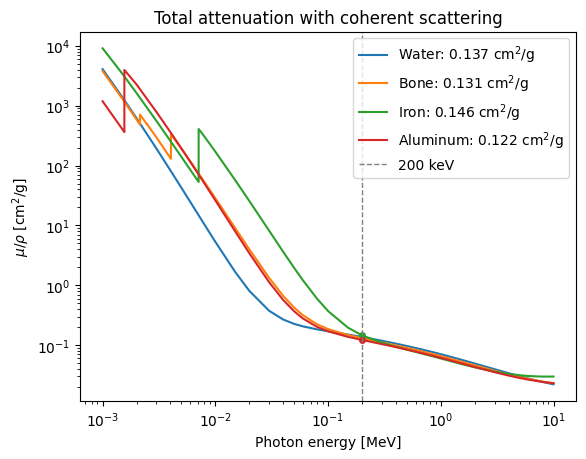

In [2]:
def read_xcom(path):
    """Read an XCOM text download: energy [MeV] and mu/rho [cm^2/g]."""
    E, mu_rho = np.loadtxt(path, skiprows=2, unpack=True)
    return E, mu_rho

# name -> (file, density [g/cm^3])
files = {"water": ("data/H2O_total_mu.txt", 1.00),
         "bone":  ("data/bone_total_mu.txt", 1.92),
         "iron":  ("data/Fe_total_mu.txt", 7.87),
         "aluminum": ("data/Al_total_mu.txt", 2.70),}

# Read each file once: name -> (energies, mu/rho, density)
xcom = {}
for name, (path, rho) in files.items():
    E, mu_rho = read_xcom(path)
    xcom[name] = (E, mu_rho, rho)

def mu_at(name, energy):
    """Linear attenuation coefficient [1/mm] of `name` at `energy` [MeV]."""
    E, mu_rho, rho = xcom[name]
    mu_rho_E = np.exp(np.interp(np.log(energy), np.log(E), np.log(mu_rho)))
    return mu_rho_E * rho / 10 # convert from [cm^2/g] * [g/cm^3] to [1/mm]


E_line = 0.2                                       # MeV

for name, (E, mu_rho, rho) in xcom.items():
    # mu/rho at 60 keV, interpolated the same way as in mu_at
    mu_rho_line = np.exp(np.interp(np.log(E_line), np.log(E), np.log(mu_rho)))

    line, = plt.loglog(E, mu_rho, label=f"{name.capitalize()}: {mu_rho_line:.3f} cm$^2$/g")
    plt.plot(E_line, mu_rho_line, "o", ms=4, color=line.get_color())

plt.axvline(E_line, color="grey", ls="--", lw=1, label=f"{E_line * 1e3:.0f} keV")
plt.xlabel("Photon energy [MeV]")
plt.ylabel(r"$\mu/\rho$ [cm$^2$/g]")
plt.title("Total attenuation with coherent scattering")
plt.legend()
plt.show()


Start by defining the function making the sample image. 

In [3]:
def sample_image(materials, n_pixel, pixel_size, seed=None):
    """
    Make a sample image of circular materials.

    materials  : list of (mu, radius) pairs, radius in mm. The first is the
                 container, placed in the centre; the others go at random
                 positions inside it without overlapping.
    n_pixel    : the image is n_pixel x n_pixel
    pixel_size : mm per pixel
    seed       : a fixed number gives the same placement every run

    Returns the image and one boolean mask per material.
    """
    # Set up the random number generator
    rng = np.random.default_rng(seed)

    # Create a grid of pixel coordinates
    yy, xx = np.mgrid[:n_pixel, :n_pixel]

    # Convert radii from mm to pixels and place the circles
    radii = [r / pixel_size for _, r in materials]
    R, c = radii[0], (n_pixel - 1) / 2

    if R > n_pixel / 2:
        raise ValueError("The container does not fit in the image")

    # Place the container in the centre, then try to place the others randomly
    centres = [(c, c)]
    for r in radii[1:]:
        # Try 1000 times to place the circle without overlapping the others and inside the container
        for _ in range(1000):
            x, y = rng.uniform(c - (R - r), c + (R - r), size=2)
            inside = np.hypot(x - c, y - c) <= R - r - 1
            free = all(np.hypot(x - xj, y - yj) >= r + rj + 1
                       for (xj, yj), rj in zip(centres[1:], radii[1:]))
            if inside and free:
                centres.append((x, y))
                break
        else:
            raise RuntimeError("Could not place all circles; try smaller or fewer")

    # Create boolean masks for each material; True if the material is present, False otherwise. The first mask is the container, the others are the materials inside it.
    masks = [(xx - x) ** 2 + (yy - y) ** 2 <= r ** 2 for (x, y), r in zip(centres, radii)]
    if len(masks) > 1:
        masks[0] &= ~np.any(masks[1:], axis=0)          # holes in the container

    # Create the image by assigning the linear attenuation coefficient mu to each pixel according to the masks
    image = np.zeros((n_pixel, n_pixel))
    for (mu, _), mask in zip(materials, masks):
        image[mask] = mu

    # Centres in mm, in the same coordinates as plots with extent=(0, L_img, L_img, 0)
    centres_mm = [((x + 0.5) * pixel_size, (y + 0.5) * pixel_size) for x, y in centres]
    
    return image, masks, centres_mm

Making and plotting the sample image.

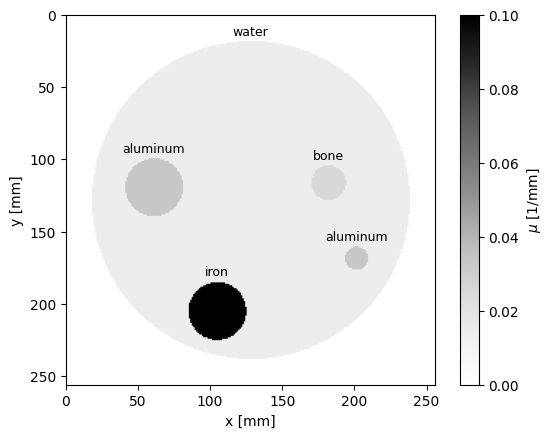

In [4]:
n_pixel = 256
pixel_size = 1.0                     # mm per pixel
L_img = n_pixel * pixel_size
ext = (0, L_img, L_img, 0) # extent for the plots
photon_energy = 0.2                   # MeV = 60 keV, one enrgy -> monochromatic beam
# material, radius [mm] pairs. The first is the container, the others are inside it.
sample = [("water", 110.0),
          ("bone", 12.0),
          ("aluminum", 8.0),
          ("aluminum", 20.0),
          ("iron", 20.0)]

materials = [(mu_at(name, photon_energy), r) for name, r in sample]
image, masks, centres = sample_image(materials, n_pixel=n_pixel, pixel_size=pixel_size, seed=42)

plt.imshow(image, cmap="Greys", vmin=0, vmax=0.1, extent=ext)
plt.colorbar(label=r"$\mu$ [1/mm]")
for (name, radius), (cx, cy) in zip(sample, centres):
    plt.text(cx, cy - radius - 2, name, ha="center", va="bottom", fontsize=9)
plt.xlabel("x [mm]")
plt.ylabel("y [mm]")
plt.show()





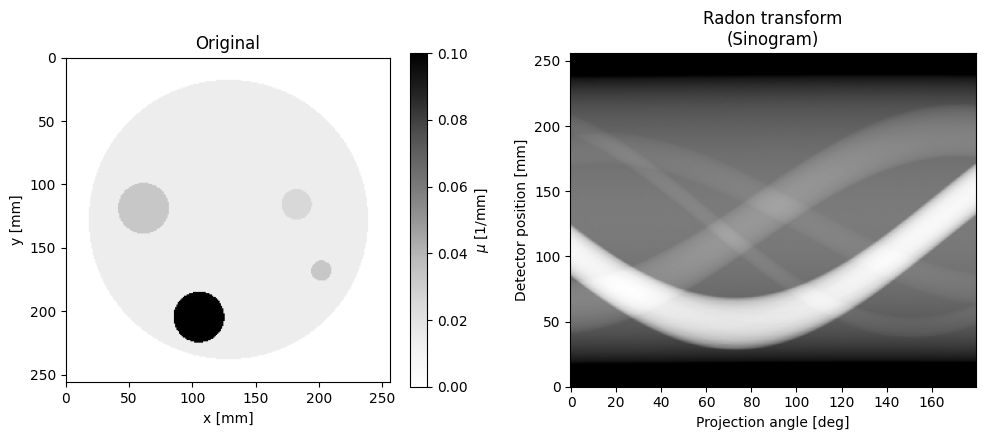

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

ax1.set_title("Original")
im1 = ax1.imshow(image, cmap="Greys", vmin=0, vmax=0.1, extent=ext)
ax1.set_xlabel("x [mm]")
ax1.set_ylabel("y [mm]")
fig.colorbar(im1, ax=ax1, label=r"$\mu$ [1/mm]")

# Compute the Radon transform (sinogram) of the image
theta_max = 180.0 # change this to see the effect of number of projections on the reconstruction
theta = np.linspace(0.0, theta_max, max(image.shape), endpoint=False)
sinogram = radon(image, theta=theta)         # sum of mu over the pixels along each ray [1/mm * px], assumes parallel rays
dtheta = theta_max / len(theta)              # angle step [deg]
det_len = sinogram.shape[0] * pixel_size     # detector length [mm]

ax2.set_title("Radon transform\n(Sinogram)")
ax2.set_xlabel("Projection angle [deg]")
ax2.set_ylabel("Detector position [mm]")
im2 = ax2.imshow(
    sinogram * pixel_size,                   # line integral of mu, unitless
    cmap=plt.cm.Greys_r,
    extent=(-dtheta / 2, theta_max - dtheta / 2, 0, det_len),   # 0 at the bottom
    origin="lower",                          # row 0 drawn at the bottom
    aspect='auto')

fig.tight_layout()
plt.show()

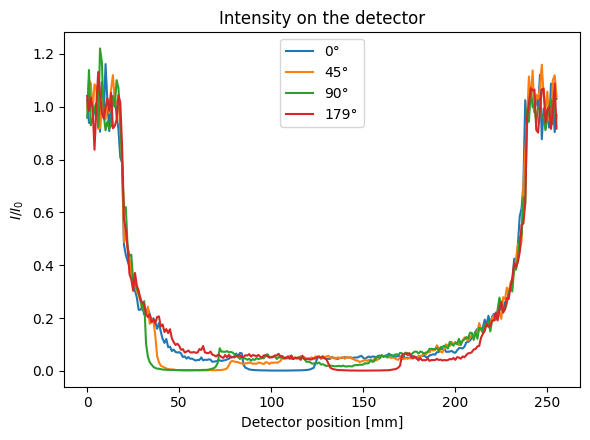

In [6]:
# Computing the intensity on the detector using Beer-Lambert law
I0 = 1.0                                                   # incoming intensity
I = I0 * np.exp(-sinogram * pixel_size )                   # transmitted intensity

# Add gaussian noise to the sinogram and compute the corresponding intensity
mean = 0.0
std_dev = 0.01 * sinogram.max()                            # 1 % of the largest value in the sinogram
noise = np.random.normal(mean, std_dev, sinogram.shape)

sinogram_noisy = sinogram + noise
I_noisy = I0 * np.exp(-sinogram_noisy * pixel_size ) 

#  Plotting intensity on the detector for a few angles
fig, ax = plt.subplots(figsize=(6, 4.5))
for angle in [ theta[0], theta[len(theta)//4], theta[len(theta)//2], theta[-1] ]:
    k = np.argmin(np.abs(theta - angle))                   # column closest to this angle
    det = np.arange(I_noisy.shape[0]) * pixel_size
    ax.plot(det, I_noisy[:, k], label=f"{theta[k]:.0f}°")
ax.set_title("Intensity on the detector")
ax.set_xlabel("Detector position [mm]")
ax.set_ylabel("$I/I_0$")
# ax.set_yscale("log")                                       # logarithmic scale for better visibility of low intensities
ax.legend()
fig.tight_layout()
plt.show()


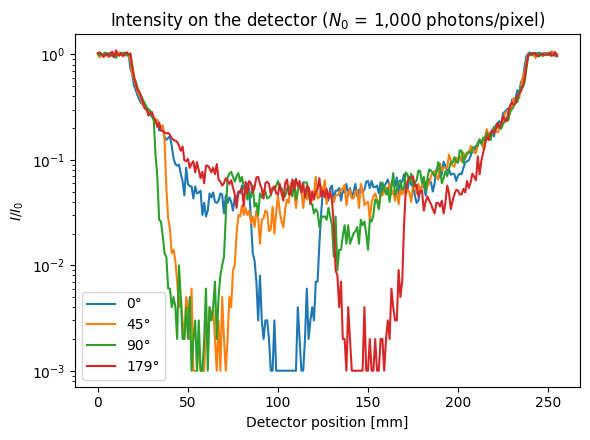

In [7]:
# Computing the intensity on the detector using Beer-Lambert law
I0 = 1.0
N0 = 1e3
                                       # photons per detector pixel without object
I = I0 * np.exp(-sinogram * pixel_size)                    # Beer-Lambert
num_events = N0 * I / I0                                   # number of photons sent times the fraction that gets through the object
counts = np.random.poisson(num_events)                     # Poisson noise on photon counts
counts = np.maximum(counts, 1)                             # avoid log(0) for rays with no photons
I_noisy = I0 * counts / N0
sinogram_noisy = -np.log(I_noisy / I0) / pixel_size

#  Plotting intensity on the detector for a few angles
fig, ax = plt.subplots(figsize=(6, 4.5))
det = np.arange(I_noisy.shape[0]) * pixel_size
for angle in [theta[0], theta[len(theta)//4], theta[len(theta)//2], theta[-1]]:
    k = np.argmin(np.abs(theta - angle))
    ax.plot(det, I_noisy[:, k], label=f"{theta[k]:.0f}°")
ax.set_title(f"Intensity on the detector ($N_0$ = {N0:,.0f} photons/pixel)")
ax.set_xlabel("Detector position [mm]")
ax.set_ylabel("$I/I_0$")
ax.set_yscale("log")
ax.legend()
fig.tight_layout()
plt.show()


FBP rms reconstruction error: 0.00813


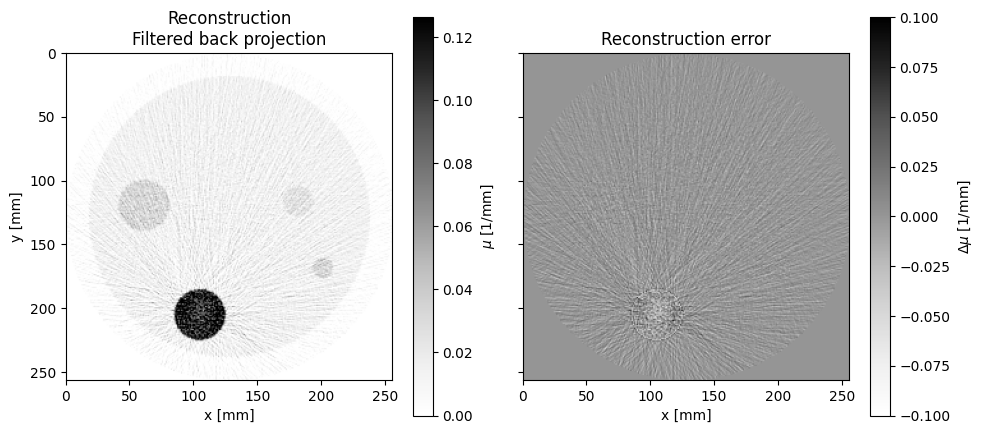

In [8]:
reconstruction_fbp = iradon(sinogram_noisy, theta=theta, filter_name='ramp')
error = reconstruction_fbp - image
print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error**2)):.3g}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)

im1 = ax1.imshow(reconstruction_fbp, cmap="Greys", vmin=0, vmax=(1.1*image.max()), extent=ext)
ax1.set_title("Reconstruction\nFiltered back projection")
fig.colorbar(im1, ax=ax1, label=r"$\mu$ [1/mm]")

im2 = ax2.imshow(error, cmap="Greys", vmin=-0.1, vmax=0.1, extent=ext)
ax2.set_title("Reconstruction error")
fig.colorbar(im2, ax=ax2, label=r"$\Delta\mu$ [1/mm]")

for ax in (ax1, ax2):
    ax.set_xlabel("x [mm]")
ax1.set_ylabel("y [mm]")
fig.tight_layout()
plt.show()


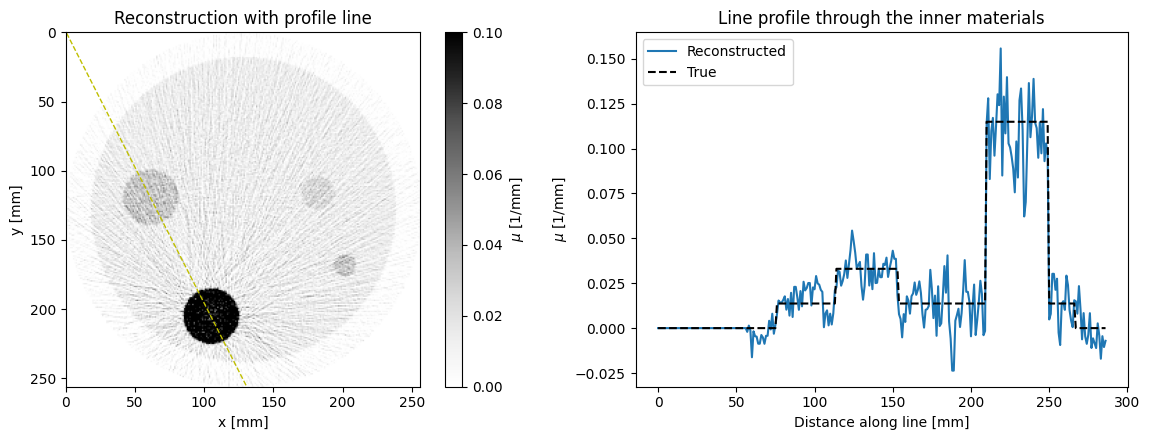

In [9]:
# Line through the centres [mm] of two disks
(x1, y1), (x2, y2) = centres[3], centres[4] # choose between the materials inside the container, numbers between 1 and 4, inclusive. 0 is the container
length = np.hypot(x2 - x1, y2 - y1)
ux, uy = (x2 - x1) / length, (y2 - y1) / length       # direction of the line, length 1

# Points along the line, one pixel apart, keeping only those inside the image
s = np.arange(-L_img, L_img, pixel_size)              # distance from centre 1 [mm]
line_x = x1 + s * ux
line_y = y1 + s * uy
in_image = (line_x >= 0) & (line_x < L_img) & (line_y >= 0) & (line_y < L_img)
line_x, line_y, s = line_x[in_image], line_y[in_image], s[in_image]

# Value of the pixel each point lies in (pixel i covers i to i+1 pixel widths)
rows = (line_y / pixel_size).astype(int)
cols = (line_x / pixel_size).astype(int)
prof_rec = reconstruction_fbp[rows, cols]
prof_true = image[rows, cols]
dist = s - s[0]                                       # distance along the line [mm]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

im = ax1.imshow(reconstruction_fbp, cmap="Greys", vmin=0, vmax=0.1, extent=ext)
ax1.plot(line_x, line_y, "y--", lw=1)
ax1.set_xlabel("x [mm]")
ax1.set_ylabel("y [mm]")
ax1.set_title("Reconstruction with profile line")
fig.colorbar(im, ax=ax1, label=r"$\mu$ [1/mm]")

ax2.plot(dist, prof_rec, label="Reconstructed")
ax2.plot(dist, prof_true, "k--", label="True")
ax2.set_xlabel("Distance along line [mm]")
ax2.set_ylabel(r"$\mu$ [1/mm]")
ax2.set_title("Line profile through the inner materials")
ax2.legend()

fig.tight_layout()
plt.show()



## Checking with Shepp-Logan Phantom

Code taken from https://scikit-image.org/docs/stable/auto_examples/transform/plot_radon_transform.html 

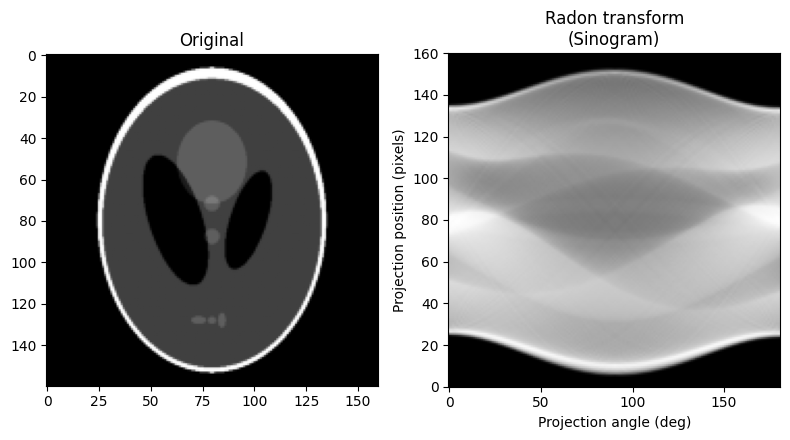

In [10]:
image = shepp_logan_phantom()
image = rescale(image, scale=0.4, mode='reflect', channel_axis=None)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5))

ax1.set_title("Original")
ax1.imshow(image, cmap=plt.cm.Greys_r)

theta = np.linspace(0.0, 180.0, max(image.shape), endpoint=False)
sinogram = radon(image, theta=theta)
dx, dy = 0.5 * 180.0 / max(image.shape), 0.5 / sinogram.shape[0]
ax2.set_title("Radon transform\n(Sinogram)")
ax2.set_xlabel("Projection angle (deg)")
ax2.set_ylabel("Projection position (pixels)")
ax2.imshow(
    sinogram,
    cmap=plt.cm.Greys_r,
    extent=(-dx, 180.0 + dx, -dy, sinogram.shape[0] + dy),
    aspect='auto',
)

fig.tight_layout()
plt.show()

FBP rms reconstruction error: 0.0283
FBP rms reconstruction error (noisy): 0.0334


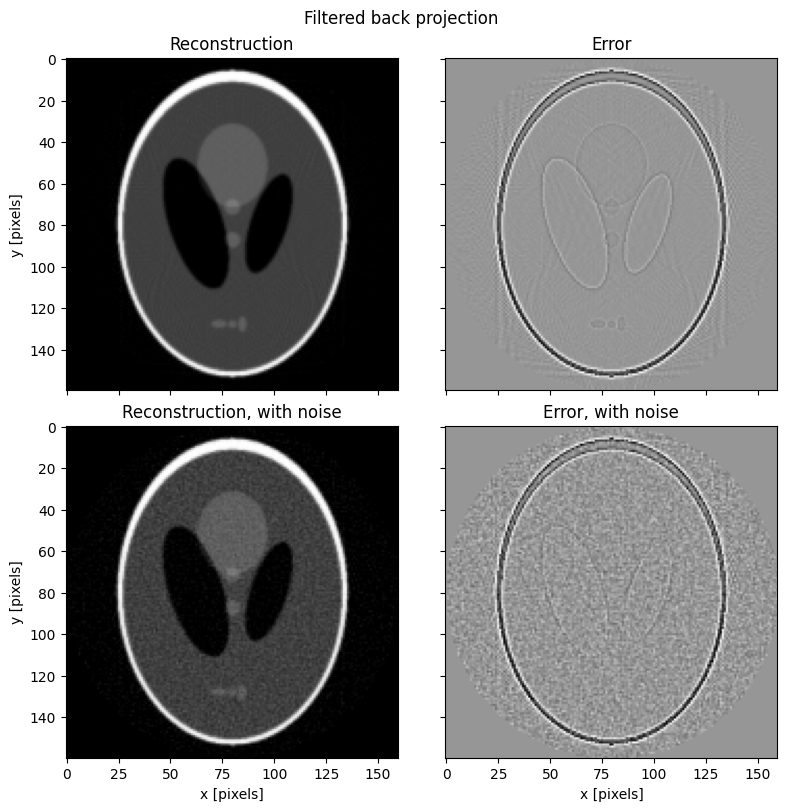

In [11]:
# Add noise to the sinogram and compute the corresponding intensity
mean = 0.0
std_dev = 0.01 * sinogram.max()                            # 1 % of the largest value in the sinogram
noise = np.random.normal(mean, std_dev, sinogram.shape)

sinogram_noisy = sinogram + noise
reconstruction_fbp = iradon(sinogram, theta=theta, filter_name='ramp')
error = reconstruction_fbp - image
print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error**2)):.3g}')

reconstruction_fbp_noisy = iradon(sinogram_noisy, theta=theta, filter_name='ramp')
error_noisy = reconstruction_fbp_noisy - image
print(f'FBP rms reconstruction error (noisy): {np.sqrt(np.mean(error_noisy**2)):.3g}')

vmax = image.max()
rec_kwargs = dict(cmap="Greys_r", vmin=0, vmax=vmax)
err_kwargs = dict(cmap="Greys_r", vmin=-0.2 * vmax, vmax=0.2 * vmax)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(8, 8), sharex=True, sharey=True,
                                             layout="constrained")
fig.suptitle("Filtered back projection")

im1 = ax1.imshow(reconstruction_fbp, **rec_kwargs)
ax1.set_title("Reconstruction")
im2 = ax2.imshow(error, **err_kwargs)
ax2.set_title("Error")
ax3.imshow(reconstruction_fbp_noisy, **rec_kwargs)
ax3.set_title("Reconstruction, with noise")
ax4.imshow(error_noisy, **err_kwargs)
ax4.set_title("Error, with noise")

for ax in (ax3, ax4):
    ax.set_xlabel("x [pixels]")
for ax in (ax1, ax3):
    ax.set_ylabel("y [pixels]")
plt.show()
